# Проект: интеллектуальная защита картографических сервисов от несанкционированного скачивания

Пайплайн:
1. Экспорт логов из OpenSearch
2. Объединение и разметка (clean / synthetic)
3. Построение окон и признаков
4. Сравнение моделей anomaly detection
5. Перебор гиперпараметров + кривые обучения
6. Сохранение артефакта модели

# 1.Экспорт логов с Opensearch

In [63]:
from __future__ import annotations
import argparse
import json
import os
from datetime import datetime
from zoneinfo import ZoneInfo
import pandas as pd
import requests
import urllib3
import urllib3
from argparse import Namespace
import sys
from dotenv import load_dotenv
import numpy as np
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt
import re
from sklearn.metrics import (
    precision_score, recall_score, f1_score, accuracy_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)


Нам потребуется функция, с помощью которой описываем интерфейс командной строки
1) Создаём ArgumentParser
2) регистрируем аргументы 
3) возвращаем Namespace с полями gte, local, tz, index, node, user, password, size, json_out, csv_out.

In [64]:
DEFAULT_INDEX = "requests"
DEFAULT_NODE = "https://localhost:9200"
def parse_args() -> argparse.Namespace:
    p = argparse.ArgumentParser()
    g = p.add_mutually_exclusive_group(required=True)
    g.add_argument("--gte",)
    g.add_argument("--local",)
    p.add_argument(
        "--tz",
        default="Europe/Moscow",
        help='Имя IANA-зоны для --local (по умолчанию Europe/Moscow)',
    )
    p.add_argument("--index", default=os.environ.get("OPENSEARCH_INDEX", DEFAULT_INDEX))
    p.add_argument("--node", default=os.environ.get("OPENSEARCH_NODE", DEFAULT_NODE))
    p.add_argument("--user", default=os.environ.get("OPENSEARCH_USER", "admin"))
    p.add_argument("--password",default=os.environ.get("OPENSEARCH_PASSWORD", ""),)
    p.add_argument("--size", type=int, default=10_000, help="Максимум хитов за запрос")
    p.add_argument(
        "--json-out",
        default="tmp_files/requests_raw.json",
        help="Сырые хиты OpenSearch (JSON)",
    )
    p.add_argument(
        "--csv-out",
        default="tmp_files/requests_raw.csv",
        help="Плоская таблица для pandas / ML",
    )
    return p.parse_args()


Также потребуется функция чтобы привести время в единый вид

In [65]:
def gte_iso_from_args(ns: argparse.Namespace) -> str:
    if ns.gte:
        return ns.gte
    dt = datetime.strptime(ns.local.strip(), "%d.%m.%Y %H:%M")
    dt = dt.replace(tzinfo=ZoneInfo(ns.tz))
    return dt.astimezone(ZoneInfo("UTC")).strftime("%Y-%m-%dT%H:%M:%S.%f")[:-3] + "Z"

Делаем запрос на получение логов

In [66]:
def fetch_scroll(
    node: str,
    index: str,
    auth: tuple[str, str],
    gte_iso: str,
    size: int,
) -> list[dict]:
    url = f"{node.rstrip('/')}/{index}/_search"
    q = {
        "query": {"range": {"requestTime": {"gte": gte_iso}}},
        "size": size,
        "sort": [{"requestTime": {"order": "asc"}}],
    }
    r = requests.post(
        url,
        auth=auth,
        json=q,
        headers={"Content-Type": "application/json"},
        verify=False,
        timeout=120,
    )
    r.raise_for_status()
    data = r.json()
    return data.get("hits", {}).get("hits", [])



Преобразовываем в csv для удобного чтения

In [67]:
def hits_to_csv(hits: list[dict]) -> pd.DataFrame:
    rows = []
    for hit in hits:
        s = hit.get("_source", {})
        p = s.get("parameters", {}) or {}
        rows.append(
            {
                "requestTime": s.get("requestTime"),
                "userIp": s.get("userIp"),
                "x": p.get("x"),
                "y": p.get("y"),
                "z": p.get("z"),
            }
        )
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    df["requestTime"] = pd.to_datetime(df["requestTime"], errors="coerce", utc=True)
    for c in ["x", "y", "z"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    return df.dropna(subset=["requestTime", "x", "y", "z"]).sort_values("requestTime")



In [68]:

def main() -> None:
    ns = parse_args()


    gte_iso = gte_iso_from_args(ns)
    auth = (ns.user, ns.password)

    urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

    hits = fetch_scroll(ns.node, ns.index, auth, gte_iso, ns.size)

    with open(ns.json_out, "w", encoding="utf-8") as f:
        json.dump({"hits": {"hits": hits}}, f, ensure_ascii=False, indent=2)

    df = hits_to_csv(hits)
    df.to_csv(ns.csv_out, index=False)

    print(f"Дата от: {gte_iso}")
    print(f"вхождений: {len(hits)}")
    print(f"строк всего: {len(df)}")
    print(f"сохранено: {ns.json_out}, {ns.csv_out}")



load_dotenv() 
sys.argv = [
    "export.py",
    "--local", "01.10.2024 00:00",  
    "--size", "10000",
]
main() # проверим что он собирает логи как и в былые времена

Дата от: 2024-09-30T21:00:00.000Z
вхождений: 322
строк всего: 322
сохранено: tmp_files/requests_raw.json, tmp_files/requests_raw.csv


## 2. Объединение и разметка (clean / synthetic)

Читаем файлы json

In [69]:
# предварительно берем логи как реальных пользователей так и явно запрошенных черех скрипты. т е ручками переименовываем requests_raw в зависимости от типа

files = [
    ("tmp_files/requests_raw_clean.json", "clean"), 
    ("tmp_files/requests_raw_synthetic.json", "synthetic"),
]

out = r"tmp_files/requests_merged_labeled.csv"

rows = []
for path, label in files:
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    for hit in data["hits"]["hits"]:
        s = hit.get("_source", {})
        p = s.get("parameters", {}) or {}
        session_id = p.get("sessionId", "")

        rows.append({
            "requestTime": s.get("requestTime"),
            "userIp": s.get("userIp"),
            "sessionId": session_id,      # оставляем для дебага/группировки
            "hasSessionId": int(bool(session_id)),
            "x": p.get("x"),
            "y": p.get("y"),
            "z": p.get("z"),
            "sourceLabel": label,         # только для оценки, НЕ фича
        })

Собираем в датафрейм и чистим

In [70]:
df = pd.DataFrame(rows)
df["requestTime"] = pd.to_datetime(df["requestTime"], errors="coerce", utc=True)
for c in ["x", "y", "z"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(subset=["requestTime", "x", "y", "z"]).sort_values("requestTime")
df.to_csv(out, index=False)

print("Сохранено как :", out)
print("Строк:", len(df))
print(df["sourceLabel"].value_counts().to_string())
print("hasSessionId by label:")
print(df.groupby("sourceLabel")["hasSessionId"].mean().to_string())

Сохранено как : tmp_files/requests_merged_labeled.csv
Строк: 7331
sourceLabel
synthetic    7009
clean         322
hasSessionId by label:
sourceLabel
clean        0.0
synthetic    0.0


# 3. Построение окон и признаков

Обозначим признаки и построким 30 окон с шагом 5

In [71]:
WINDOW = 30
STEP = 5

FEATURE_COLS = [
    "req_count", "x_std", "y_std", "z_std",
    "x_unique", "y_unique", "z_unique",
    "mean_abs_dx", "mean_abs_dy",
    "mean_dt", "std_dt", "min_dt", "max_dt"
]

Сгруппируем запросы в сессии 

In [72]:
def make_group_id(df_in: pd.DataFrame) -> pd.Series:
    sid = df_in["sessionId"].fillna("").astype(str).str.strip()
    return np.where(
        sid != "",
        df_in["userIp"].astype(str) + "|" + sid,
        df_in["userIp"].astype(str) + "|no-session",
    )

Построим окна

In [73]:
def build_windows(df_in: pd.DataFrame, window: int, step: int) -> pd.DataFrame:
    df_in = df_in.copy()
    df_in["groupId"] = make_group_id(df_in)
    rows = []
    
    for _, g in df_in.groupby("groupId"):
        g = g.sort_values("requestTime").reset_index(drop=True)
        if len(g) < window:
            continue
            
        for i in range(0, len(g) - window + 1, step):
            w = g.iloc[i:i+window]
            x = w["x"].to_numpy()
            y = w["y"].to_numpy()
            z = w["z"].to_numpy()
            t = w["requestTime"].astype("int64").to_numpy() / 1e9

            dx = np.diff(x)
            dy = np.diff(y)
            dt = np.diff(t)
            dt = np.where(dt <= 0, 1e-6, dt)

            rows.append({
                "groupId": w["groupId"].iloc[0],
                "startTime": w["requestTime"].iloc[0],
                "endTime": w["requestTime"].iloc[-1],
                "sourceLabel": w["sourceLabel"].mode().iloc[0],
                "req_count": len(w),
                "x_std": float(np.std(x)), "y_std": float(np.std(y)), "z_std": float(np.std(z)),
                "x_unique": int(len(np.unique(x))), "y_unique": int(len(np.unique(y))), "z_unique": int(len(np.unique(z))),
                "mean_abs_dx": float(np.mean(np.abs(dx))) if len(dx) else 0.0,
                "mean_abs_dy": float(np.mean(np.abs(dy))) if len(dy) else 0.0,
                "mean_dt": float(np.mean(dt)) if len(dt) else 0.0,
                "std_dt": float(np.std(dt)) if len(dt) else 0.0,
                "min_dt": float(np.min(dt)) if len(dt) else 0.0,
                "max_dt": float(np.max(dt)) if len(dt) else 0.0,
            })
    return pd.DataFrame(rows)

In [74]:
# Запускаем построение окон
wdf = build_windows(df, window=WINDOW, step=STEP)
wdf.to_csv("tmp_files/windows_features.csv", index=False)

print("Всего окон:", len(wdf))
print(wdf["sourceLabel"].value_counts().to_string())

Всего окон: 1461
sourceLabel
synthetic    1399
clean          62


# 4. Сравнение моделей anomaly detection

In [75]:
INPUT_CSV = "tmp_files/windows_features.csv"
OUT_DIR = "tmp_files/plots_models"
os.makedirs(OUT_DIR, exist_ok=True)

Переводим текстовые метки в бинарные (0 и 1).

In [76]:
def to_binary(labels: pd.Series) -> np.ndarray:
    return (labels == "synthetic").astype(int).to_numpy()

Переводим ответы моделей в 0 и 1

In [77]:
def pred_to_binary(pred_raw: np.ndarray) -> np.ndarray:
    return (pred_raw == -1).astype(int)

Ниже вспомогашка для адеватного сохранения

In [78]:
def safe_name(s: str) -> str:
    return re.sub(r"[^a-zA-Z0-9_\-]+", "_", s)

Ниже получаем статистику у модели

In [79]:
def get_anomaly_score(model, X_test, y_pred_bin):
    if hasattr(model, "decision_function"):
        return -model.decision_function(X_test)
    if hasattr(model, "score_samples"):
        return -model.score_samples(X_test)
    return y_pred_bin.astype(float)

Работа самой модели

In [80]:
def evaluate_model(name, model, X_train, X_test, y_true, out_dir):
    model.fit(X_train)
    pred_raw = model.predict(X_test)
    y_pred = pred_to_binary(pred_raw)
    anomaly_score = get_anomaly_score(model, X_test, y_pred)

    plot_curves(name, y_true, anomaly_score, out_dir)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    return {
        "model": name,
        "precision_synthetic": precision_score(y_true, y_pred, zero_division=0),
        "recall_synthetic": recall_score(y_true, y_pred, zero_division=0),
        "f1_synthetic": f1_score(y_true, y_pred, zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, anomaly_score),
        "pr_auc": average_precision_score(y_true, anomaly_score),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

Графики работы

In [81]:
def plot_curves(model_name, y_true, anomaly_score, out_dir):
    name = safe_name(model_name)

    # ROC
    fpr, tpr, _ = roc_curve(y_true, anomaly_score)
    roc_auc = roc_auc_score(y_true, anomaly_score)
    plt.figure(figsize=(6, 6))
    plt.plot(fpr, tpr, label=f"ROC AUC = {roc_auc:.4f}")
    plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
    plt.xlabel("FPR")
    plt.ylabel("TPR")
    plt.title(f"ROC — {model_name}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{out_dir}\\roc_{name}.png", dpi=150)
    plt.close()

    # PR
    p, r, _ = precision_recall_curve(y_true, anomaly_score)
    pr_auc = average_precision_score(y_true, anomaly_score)
    plt.figure(figsize=(6, 6))
    plt.plot(r, p, label=f"PR AUC = {pr_auc:.4f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"PR — {model_name}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{out_dir}\\pr_{name}.png", dpi=150)
    plt.close()

    # Score distribution
    clean = anomaly_score[y_true == 0]
    synth = anomaly_score[y_true == 1]
    plt.figure(figsize=(8, 5))
    plt.hist(clean, bins=35, alpha=0.6, density=True, label="clean")
    plt.hist(synth, bins=35, alpha=0.6, density=True, label="synthetic")
    plt.xlabel("anomaly_score")
    plt.ylabel("density")
    plt.title(f"Score distribution — {model_name}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{out_dir}\\score_hist_{name}.png", dpi=150)
    plt.close()


Обучение IsolationForest...

Обучение OneClassSVM_rbf...

Обучение LOF_novelty...


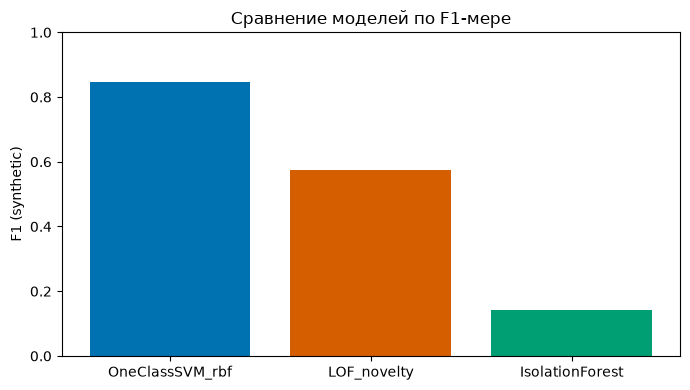


=== ИТОГОВОЕ СРАВНЕНИЕ ===


,model,precision_synthetic,recall_synthetic,f1_synthetic,accuracy,roc_auc,pr_auc,TN,FP,FN,TP
1,OneClassSVM_rbf,0.994197,0.734811,0.845047,0.741958,0.908679,0.995580,56,6,371,1028
2,LOF_novelty,0.992995,0.405289,0.575635,0.427789,0.831619,0.990497,58,4,832,567
0,IsolationForest,0.964286,0.077198,0.142952,0.113621,0.816851,0.978431,58,4,1291,108


In [ ]:
# Читаем окна
df = pd.read_csv(INPUT_CSV)
X = df[FEATURE_COLS].to_numpy()
y = to_binary(df["sourceLabel"])

# Берем только чистые данные для обучения
train_mask = df["sourceLabel"] == "clean"
X_train = df.loc[train_mask, FEATURE_COLS].to_numpy()
X_test = X

if len(X_train) < 10:
    print("Слишком мало чистых данных (clean)")
else:
    models = [
        ("IsolationForest", IsolationForest(n_estimators=500, contamination=0.05, random_state=42)),
        ("OneClassSVM_rbf", Pipeline([
            ("scaler", StandardScaler()),
            ("ocsvm", OneClassSVM(kernel="rbf", nu=0.05, gamma="scale"))
        ])),
        ("LOF_novelty", Pipeline([
            ("scaler", StandardScaler()),
            ("lof", LocalOutlierFactor(n_neighbors=35, contamination=0.05, novelty=True))
        ])),
    ]

    rows = []
    for name, model in models:
        print(f"\nОбучение {name}...")
        rows.append(evaluate_model(name, model, X_train, X_test, y, OUT_DIR))

    out_df = pd.DataFrame(rows).sort_values("f1_synthetic", ascending=False)
    out_df.to_csv("tmp_files/model_compare.csv", index=False)

   
    plt.figure(figsize=(7, 4))
    plt.bar(out_df["model"], out_df["f1_synthetic"], color=['#0072B2', '#D55E00', '#009E73'])
    plt.ylim(0, 1)
    plt.ylabel("F1 (synthetic)")
    plt.title("Сравнение моделей по F1-мере")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/models_f1_compare.png", dpi=150)
    plt.show()

    print("\n=== ИТОГОВОЕ СРАВНЕНИЕ ===")
    display(out_df)